# Vision Transformer on CIFAR10

ViT from scratch (PyTorch Lightning). Adapted from UvA DL Tutorial 15 (P. Lippe).

In [1]:
## Standard libraries
import os
import site
import importlib
import numpy as np
import random
import math
import json
from functools import partial
from PIL import Image

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
# IPython.display.set_matplotlib_formats removed in IPython 8+
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
from matplotlib.colors import to_rgb
import matplotlib
matplotlib.rcParams['image.cmap'] = 'cividis'  # plt.set_cmap spawns empty fig
matplotlib.rcParams['lines.linewidth'] = 2.0
import seaborn as sns
sns.reset_orig()

## tqdm for loading bars
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim

## Torchvision
import torchvision
from torchvision.datasets import CIFAR10
from torchvision import transforms

# PyTorch Lightning + tensorboard (missing in Colab / jupyter pytorch-notebook image)
try:
    import pytorch_lightning as pl
    import tensorboard
except ModuleNotFoundError:
    # quoted: unquoted >= is shell redirect
    %pip install --quiet "pytorch-lightning>=2.0" tensorboard
    # k8s pod: PIP_USER -> user site on PVC; may not exist at kernel start -> add w/o restart
    site.addsitedir(site.getusersitepackages())
    importlib.invalidate_caches()
    import pytorch_lightning as pl
from pytorch_lightning.callbacks import LearningRateMonitor, ModelCheckpoint

# Import tensorboard
%load_ext tensorboard

# Persistent storage: PVC in k8s pod, else parent dir (Colab/local)
WORK_DIR = "/home/jovyan/work" if os.path.isdir("/home/jovyan/work") else ".."
# Path to the folder where the datasets are/should be downloaded (e.g. CIFAR10)
DATASET_PATH = os.path.join(WORK_DIR, "data")
# Path to the folder where the pretrained models are saved
CHECKPOINT_PATH = os.path.join(WORK_DIR, "saved_models/tutorial15")
# True: ignore downloaded ViT.ckpt, train on GPU (~1h on modern GPU)
TRAIN_FROM_SCRATCH = False
# DataLoader workers; pod CPU limit = 4, Colab = 2
NUM_WORKERS = min(4, os.cpu_count() or 1)

# Setting the seed
pl.seed_everything(42)

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("WORK_DIR:", os.path.abspath(WORK_DIR), "| workers:", NUM_WORKERS)


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


Seed set to 42


Device: cuda:0 NVIDIA H200-3-71C MIG 3g.71gb
WORK_DIR: /home/jovyan/work | workers: 4


Download pretrained checkpoint + tensorboard logs.

In [2]:
import urllib.request
from urllib.error import HTTPError
# Github URL where saved models are stored for this tutorial
base_url = "https://raw.githubusercontent.com/phlippe/saved_models/main/"
# Files to download
pretrained_files = ["tutorial15/ViT.ckpt", "tutorial15/tensorboards/ViT/events.out.tfevents.ViT",
                    "tutorial5/tensorboards/ResNet/events.out.tfevents.resnet"]
# Create checkpoint path if it doesn't exist yet
os.makedirs(CHECKPOINT_PATH, exist_ok=True)

# For each file, check whether it already exists. If not, try downloading it.
for file_name in pretrained_files:
    file_path = os.path.join(CHECKPOINT_PATH, file_name.split("/",1)[1])
    if "/" in file_name.split("/",1)[1]:
        os.makedirs(file_path.rsplit("/",1)[0], exist_ok=True)
    if not os.path.isfile(file_path):
        file_url = base_url + file_name
        print(f"Downloading {file_url}...")
        try:
            urllib.request.urlretrieve(file_url, file_path)
        except HTTPError as e:
            print("Something went wrong. Please try to download the file from the GDrive folder, or contact the author with the full output including the following error:\n", e)

Load CIFAR10: 45k/5k train/val split, light augmentation on train.

100%|██████████| 170M/170M [34:17<00:00, 82.9kB/s] 
Seed set to 42
Seed set to 42


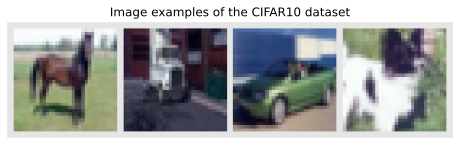

In [3]:
test_transform = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])
                                     ])
# For training, we add some augmentation. Networks are too powerful and would overfit.
train_transform = transforms.Compose([transforms.RandomHorizontalFlip(),
                                      transforms.RandomResizedCrop((32,32),scale=(0.8,1.0),ratio=(0.9,1.1)),
                                      transforms.ToTensor(),
                                      transforms.Normalize([0.49139968, 0.48215841, 0.44653091], [0.24703223, 0.24348513, 0.26158784])
                                     ])
# Loading the training dataset. We need to split it into a training and validation part
# We need to do a little trick because the validation set should not use the augmentation.
train_dataset = CIFAR10(root=DATASET_PATH, train=True, transform=train_transform, download=True)
val_dataset = CIFAR10(root=DATASET_PATH, train=True, transform=test_transform, download=True)
pl.seed_everything(42)
train_set, _ = torch.utils.data.random_split(train_dataset, [45000, 5000])
pl.seed_everything(42)
_, val_set = torch.utils.data.random_split(val_dataset, [45000, 5000])

# Loading the test set
test_set = CIFAR10(root=DATASET_PATH, train=False, transform=test_transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True, pin_memory=True, num_workers=NUM_WORKERS)
val_loader = data.DataLoader(val_set, batch_size=128, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = data.DataLoader(test_set, batch_size=128, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

# Visualize some examples
NUM_IMAGES = 4
CIFAR_images = torch.stack([val_set[idx][0] for idx in range(NUM_IMAGES)], dim=0)
img_grid = torchvision.utils.make_grid(CIFAR_images, nrow=4, normalize=True, pad_value=0.9)
img_grid = img_grid.permute(1, 2, 0)

plt.figure(figsize=(8,8))
plt.title("Image examples of the CIFAR10 dataset")
plt.imshow(img_grid)
plt.axis('off')
plt.show()
plt.close()

## Model

Split image into flattened patches (tokens).

In [4]:
def img_to_patch(x, patch_size, flatten_channels=True):
    """
    Inputs:
        x - torch.Tensor representing the image of shape [B, C, H, W]
        patch_size - Number of pixels per dimension of the patches (integer)
        flatten_channels - If True, the patches will be returned in a flattened format
                           as a feature vector instead of a image grid.
    """
    B, C, H, W = x.shape
    x = x.reshape(B, C, H//patch_size, patch_size, W//patch_size, patch_size)
    x = x.permute(0, 2, 4, 1, 3, 5) # [B, H', W', C, p_H, p_W]
    x = x.flatten(1,2)              # [B, H'*W', C, p_H, p_W]
    if flatten_channels:
        x = x.flatten(2,4)          # [B, H'*W', C*p_H*p_W]
    return x

Visualize patches: 32×32 image, patch size 4 → 64 patches.

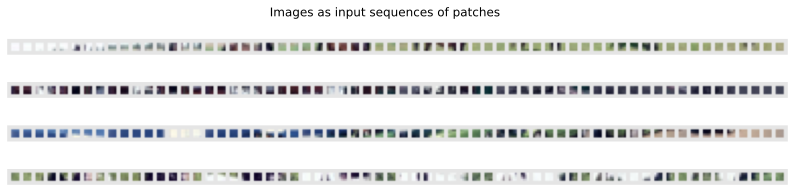

In [5]:
img_patches = img_to_patch(CIFAR_images, patch_size=4, flatten_channels=False)

fig, ax = plt.subplots(CIFAR_images.shape[0], 1, figsize=(14,3))
fig.suptitle("Images as input sequences of patches")
for i in range(CIFAR_images.shape[0]):
    img_grid = torchvision.utils.make_grid(img_patches[i], nrow=64, normalize=True, pad_value=0.9)
    img_grid = img_grid.permute(1, 2, 0)
    ax[i].imshow(img_grid)
    ax[i].axis('off')
plt.show()
plt.close()

Pre-LN Transformer block: attention + MLP, each with residual.

In [6]:
class AttentionBlock(nn.Module):

    def __init__(self, embed_dim, hidden_dim, num_heads, dropout=0.0):
        """
        Inputs:
            embed_dim - Dimensionality of input and attention feature vectors
            hidden_dim - Dimensionality of hidden layer in feed-forward network
                         (usually 2-4x larger than embed_dim)
            num_heads - Number of heads to use in the Multi-Head Attention block
            dropout - Amount of dropout to apply in the feed-forward network
        """
        super().__init__()

        self.layer_norm_1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads,
                                          dropout=dropout)
        self.layer_norm_2 = nn.LayerNorm(embed_dim)
        self.linear = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
            nn.Dropout(dropout)
        )


    def forward(self, x):
        inp_x = self.layer_norm_1(x)
        x = x + self.attn(inp_x, inp_x, inp_x)[0]
        x = x + self.linear(self.layer_norm_2(x))
        return x

Full ViT: patch projection, CLS token, learnable pos. embeddings, Transformer, MLP head.

In [7]:
class VisionTransformer(nn.Module):

    def __init__(self, embed_dim, hidden_dim, num_channels, num_heads, num_layers, num_classes, patch_size, num_patches, dropout=0.0):
        """
        Inputs:
            embed_dim - Dimensionality of the input feature vectors to the Transformer
            hidden_dim - Dimensionality of the hidden layer in the feed-forward networks
                         within the Transformer
            num_channels - Number of channels of the input (3 for RGB)
            num_heads - Number of heads to use in the Multi-Head Attention block
            num_layers - Number of layers to use in the Transformer
            num_classes - Number of classes to predict
            patch_size - Number of pixels that the patches have per dimension
            num_patches - Maximum number of patches an image can have
            dropout - Amount of dropout to apply in the feed-forward network and
                      on the input encoding
        """
        super().__init__()

        self.patch_size = patch_size

        # Layers/Networks
        self.input_layer = nn.Linear(num_channels*(patch_size**2), embed_dim)
        self.transformer = nn.Sequential(*[AttentionBlock(embed_dim, hidden_dim, num_heads, dropout=dropout) for _ in range(num_layers)])
        self.mlp_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes)
        )
        self.dropout = nn.Dropout(dropout)

        # Parameters/Embeddings
        self.cls_token = nn.Parameter(torch.randn(1,1,embed_dim))
        self.pos_embedding = nn.Parameter(torch.randn(1,1+num_patches,embed_dim))


    def forward(self, x):
        # Preprocess input
        x = img_to_patch(x, self.patch_size)
        B, T, _ = x.shape
        x = self.input_layer(x)

        # Add CLS token and positional encoding
        cls_token = self.cls_token.repeat(B, 1, 1)
        x = torch.cat([cls_token, x], dim=1)
        x = x + self.pos_embedding[:,:T+1]

        # Apply Transforrmer
        x = self.dropout(x)
        x = x.transpose(0, 1)
        x = self.transformer(x)

        # Perform classification prediction
        cls = x[0]
        out = self.mlp_head(cls)
        return out

Lightning module: AdamW + MultiStepLR.

In [8]:
class ViT(pl.LightningModule):

    def __init__(self, model_kwargs, lr):
        super().__init__()
        self.save_hyperparameters()
        self.model = VisionTransformer(**model_kwargs)
        self.example_input_array = next(iter(train_loader))[0]

    def forward(self, x):
        return self.model(x)

    def configure_optimizers(self):
        optimizer = optim.AdamW(self.parameters(), lr=self.hparams.lr)
        lr_scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[100,150], gamma=0.1)
        return [optimizer], [lr_scheduler]

    def _calculate_loss(self, batch, mode="train"):
        imgs, labels = batch
        preds = self.model(imgs)
        loss = F.cross_entropy(preds, labels)
        acc = (preds.argmax(dim=-1) == labels).float().mean()

        self.log(f'{mode}_loss', loss)
        self.log(f'{mode}_acc', acc)
        return loss

    def training_step(self, batch, batch_idx):
        loss = self._calculate_loss(batch, mode="train")
        return loss

    def validation_step(self, batch, batch_idx):
        self._calculate_loss(batch, mode="val")

    def test_step(self, batch, batch_idx):
        self._calculate_loss(batch, mode="test")

## Experiments

Train function; loads pretrained checkpoint if present.

In [9]:
def train_model(**kwargs):
    trainer = pl.Trainer(default_root_dir=os.path.join(CHECKPOINT_PATH, "ViT"),
                         accelerator="gpu" if str(device).startswith("cuda") else "cpu",
                         devices=1,
                         max_epochs=180,
                         callbacks=[ModelCheckpoint(save_weights_only=True, mode="max", monitor="val_acc"),
                                    LearningRateMonitor("epoch")])
    trainer.logger._log_graph = True         # If True, we plot the computation graph in tensorboard
    trainer.logger._default_hp_metric = None # Optional logging argument that we don't need

    # Check whether pretrained model exists. If yes, load it and skip training
    pretrained_filename = os.path.join(CHECKPOINT_PATH, "ViT.ckpt")
    if os.path.isfile(pretrained_filename) and not TRAIN_FROM_SCRATCH:
        print(f"Found pretrained model at {pretrained_filename}, loading...")
        model = ViT.load_from_checkpoint(pretrained_filename) # Automatically loads the model with the saved hyperparameters
    else:
        pl.seed_everything(42) # To be reproducable
        model = ViT(**kwargs)
        trainer.fit(model, train_loader, val_loader)
        model = ViT.load_from_checkpoint(trainer.checkpoint_callback.best_model_path) # Load best checkpoint after training

    # Test best model on validation and test set
    val_result = trainer.test(model, val_loader, verbose=False)
    test_result = trainer.test(model, test_loader, verbose=False)
    result = {"test": test_result[0]["test_acc"], "val": val_result[0]["test_acc"]}

    return model, result

Train/evaluate with chosen hyperparameters.

In [10]:
model, results = train_model(model_kwargs={
                                'embed_dim': 256,
                                'hidden_dim': 512,
                                'num_heads': 8,
                                'num_layers': 6,
                                'patch_size': 4,
                                'num_channels': 3,
                                'num_patches': 64,
                                'num_classes': 10,
                                'dropout': 0.2
                            },
                            lr=3e-4)
print("ViT results", results)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Found pretrained model at /home/jovyan/work/saved_models/tutorial15/ViT.ckpt, loading...


Lightning automatically upgraded your loaded checkpoint from v1.6.4 to v2.6.6. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint saved_models/tutorial15/ViT.ckpt`
You are using a CUDA device ('NVIDIA H200-3-71C MIG 3g.71gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/jovyan/work/.pyuser/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

ViT results {'test': 0.7713000178337097, 'val': 0.7781999707221985}


Training curves (ViT vs ResNet).

In [11]:
# Opens tensorboard in notebook; logdir covers pretrained + own runs (ViT/lightning_logs)
# Remote kernel: forward port 6006 too, or open http://localhost:6006 in browser
%tensorboard --logdir {CHECKPOINT_PATH}


ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

## Result

ViT ≈75% test acc vs ≈90% for CNNs: no locality/translation inductive bias, CIFAR10 too small to learn it.

## Hugging Face ViT comparison

Same CIFAR10 split, two HF variants:
1. **Scratch**: same architecture/hparams as above, random init.
2. **Pretrained**: `facebook/deit-tiny-patch16-224` (closest small pretrained ViT: D=192, 12 layers, ~5.7M params) fine-tuned, images upsampled to 224.

In [20]:
try:
    from transformers import ViTConfig, ViTForImageClassification, AutoImageProcessor
except ModuleNotFoundError:
    !pip install --quiet transformers
    from transformers import ViTConfig, ViTForImageClassification, AutoImageProcessor

PRETRAINED_ID = "facebook/deit-tiny-patch16-224"

Generic Lightning wrapper for HF ViT (config → scratch, `pretrained` id → fine-tune).

In [ ]:
class HFViT(pl.LightningModule):

    def __init__(self, lr, model_kwargs=None, pretrained=None, milestones=(100, 150)):
        super().__init__()
        self.save_hyperparameters()
        if pretrained:
            self.model = ViTForImageClassification.from_pretrained(pretrained, num_labels=10, ignore_mismatched_sizes=True)
        else:
            self.model = ViTForImageClassification(ViTConfig(**model_kwargs))

    def forward(self, x):
        return self.model(pixel_values=x).logits

    def configure_optimizers(self):
        optimizer = optim.AdamW(self.parameters(), lr=self.hparams.lr)
        lr_scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(self.hparams.milestones), gamma=0.1)
        return [optimizer], [lr_scheduler]

    def _calculate_loss(self, batch, mode="train"):
        imgs, labels = batch
        preds = self(imgs)
        loss = F.cross_entropy(preds, labels)
        acc = (preds.argmax(dim=-1) == labels).float().mean()
        self.log(f'{mode}_loss', loss)
        self.log(f'{mode}_acc', acc)
        return loss

    def training_step(self, batch, batch_idx):
        return self._calculate_loss(batch, mode="train")

    def validation_step(self, batch, batch_idx):
        self._calculate_loss(batch, mode="val")

    def test_step(self, batch, batch_idx):
        self._calculate_loss(batch, mode="test")

Train fn; reuses `<CHECKPOINT_PATH>/<name>.ckpt` if present.

In [ ]:
import shutil

def train_hf(name, loaders, max_epochs, precision="32-true", **kwargs):
    train_dl, val_dl, test_dl = loaders
    trainer = pl.Trainer(default_root_dir=os.path.join(CHECKPOINT_PATH, name),
                         accelerator="gpu" if str(device).startswith("cuda") else "cpu",
                         devices=1,
                         max_epochs=max_epochs,
                         precision=precision,
                         callbacks=[ModelCheckpoint(save_weights_only=True, mode="max", monitor="val_acc"),
                                    LearningRateMonitor("epoch")])
    ckpt = os.path.join(CHECKPOINT_PATH, f"{name}.ckpt")
    if os.path.isfile(ckpt):
        print(f"Found {ckpt}, loading...")
    else:
        pl.seed_everything(42)
        trainer.fit(HFViT(**kwargs), train_dl, val_dl)
        shutil.copy(trainer.checkpoint_callback.best_model_path, ckpt)
    model = HFViT.load_from_checkpoint(ckpt)

    val_result = trainer.test(model, val_dl, verbose=False)
    test_result = trainer.test(model, test_dl, verbose=False)
    return model, {"test": test_result[0]["test_acc"], "val": val_result[0]["test_acc"]}

### 1. HF ViT from scratch

Same hparams as own ViT, same 32×32 loaders. 180 epochs → GPU, hours; lower `HF_SCRATCH_EPOCHS` for a quick run.

In [ ]:
HF_SCRATCH_EPOCHS = 180

hf_scratch_model, hf_scratch_results = train_hf(
    "HFViT_scratch", (train_loader, val_loader, test_loader), max_epochs=HF_SCRATCH_EPOCHS,
    model_kwargs=dict(image_size=32, patch_size=4, num_channels=3,
                      hidden_size=256,          # embed_dim
                      intermediate_size=512,    # hidden_dim
                      num_attention_heads=8, num_hidden_layers=6,
                      hidden_dropout_prob=0.2, attention_probs_dropout_prob=0.2,
                      num_labels=10),
    lr=3e-4)
print("HF scratch results", hf_scratch_results)

### 2. DeiT-tiny pretrained (ImageNet-1k) + fine-tune

Resize to 224 + checkpoint's normalization. Same split seed → same train/val/test images. Few epochs, small lr. GPU recommended (~1.3 GFLOPs/img, ~3× scratch).

In [21]:
IMG_SIZE = 224
processor = AutoImageProcessor.from_pretrained(PRETRAINED_ID)
norm = transforms.Normalize(processor.image_mean, processor.image_std)

pt_test_transform = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
                                        transforms.ToTensor(), norm])
pt_train_transform = transforms.Compose([transforms.RandomHorizontalFlip(),
                                         transforms.RandomResizedCrop((IMG_SIZE, IMG_SIZE), scale=(0.8, 1.0), ratio=(0.9, 1.1)),
                                         transforms.ToTensor(), norm])

pt_train_dataset = CIFAR10(root=DATASET_PATH, train=True, transform=pt_train_transform, download=True)
pt_val_dataset = CIFAR10(root=DATASET_PATH, train=True, transform=pt_test_transform, download=True)
pl.seed_everything(42)
pt_train_set, _ = torch.utils.data.random_split(pt_train_dataset, [45000, 5000])
pl.seed_everything(42)
_, pt_val_set = torch.utils.data.random_split(pt_val_dataset, [45000, 5000])
pt_test_set = CIFAR10(root=DATASET_PATH, train=False, transform=pt_test_transform, download=True)

PT_BATCH = 128
pt_loaders = (data.DataLoader(pt_train_set, batch_size=PT_BATCH, shuffle=True, drop_last=True, pin_memory=True, num_workers=4),
              data.DataLoader(pt_val_set, batch_size=PT_BATCH, shuffle=False, drop_last=False, num_workers=4),
              data.DataLoader(pt_test_set, batch_size=PT_BATCH, shuffle=False, drop_last=False, num_workers=4))

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

Seed set to 42
Seed set to 42


In [22]:
hf_pt_model, hf_pt_results = train_hf(
    "HFViT_pretrained", pt_loaders, max_epochs=3,
    precision="16-mixed" if str(device).startswith("cuda") else "32-true",
    pretrained=PRETRAINED_ID, lr=3e-5, milestones=())
print("HF pretrained results", hf_pt_results)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Seed set to 42
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 23.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-tiny-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 192]) vs model:torch.Size([10, 192])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/home/jovyan/work/.pyuser/lib/python3.13/site-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.

  | Name  | Type          

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (10 outputs left out)

Testing: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

HF pretrained results {'test': 0.953000009059906, 'val': 0.951200008392334}


### Comparison

In [ ]:
for name, r in [("Own ViT (scratch)", results),
                ("HF ViT (scratch)", hf_scratch_results),
                ("DeiT-tiny (in1k, fine-tuned)", hf_pt_results)]:
    print(f"{name:35s} val {r['val']:.2%}  test {r['test']:.2%}")